# Exercise 16 — Principal Component Analysis (PCA)

**M.Sc. Data Science · I Semester · Machine Learning Lab**  
**Department Number:** 26-PDS-011 · **Student:** Thenmozhi K

## Aim
Apply PCA to reduce the preprocessed heart disease feature space to two components and measure explained variance.

## Dataset
Expected path: `heart_disease_dataset.csv`. Obtain the dataset from an authorised source and place it at the expected path. See the [dataset guide](../datasets/README.md).

## Algorithm / Workflow
1. Load data and separate the target.
2. Identify numeric and categorical features.
3. Scale numeric features and one-hot encode categorical features.
4. Convert processed data to a dense array if required.
5. Fit PCA with two components.
6. Transform data and calculate explained variance per component.
7. Plot the two principal components.

## Implementation
The following code is copied from the existing `ex-16.py` program and split into notebook cells for interactive execution. The original Python program is unchanged.

Run cells from top to bottom. Outputs and charts are generated when executed with the dataset and required libraries available.

Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

/tmp/ipykernel_3000/3827752477.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


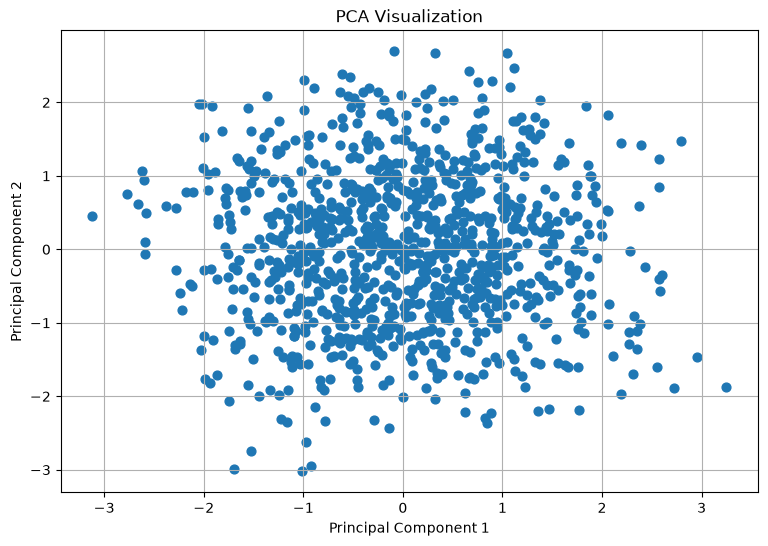

In [1]:
# EXERCISE – 16 (PRINCIPAL COMPONENT ANALYSIS)

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA

df = pd.read_csv("https://raw.githubusercontent.com/thenmozhi269/machine_learning_lab/refs/heads/main/datasets/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Check whether X_processed is sparse or already a NumPy array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("\nProcessed Data Shape:")
print(X_processed.shape)

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X_processed)

pca_df = pd.DataFrame(
    X_pca,
    columns=[
        "Principal Component 1",
        "Principal Component 2"
    ]
)

print("\nPCA Transformed Data:")
print(pca_df.head())

print("\nExplained Variance Ratio:")

print(pca.explained_variance_ratio_)

total_variance = pca.explained_variance_ratio_.sum()

print("\nTotal Variance Explained:")
print(total_variance)

print(
    "\nPercentage of Variance Explained:",
    total_variance * 100,
    "%"
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")

plt.grid(True)

plt.show()


## Result summary from the practical record
The 27 processed features were reduced to two components explaining 9.80% and 9.36% of variance respectively, 19.16% total.

This summary is transcribed from the supplied Word record; it is not a fresh notebook execution. Run the cells to produce current outputs.

## Conclusion
Summarise findings from your execution and note limitations.

## Reproducibility
Record your Python version, dataset source/version and installed dependency versions.